# 13C 化学位移预测

根据分子结构预测 13C 化学位移。利用返回的原子编号，可以把预测值标到分子结构上，也可以与实测峰比较。

NMRNet 编码分子构象，并预测所选原子的化学位移。接口负责准备构象、加载相应核种的权重，并应用模型的位移缩放参数。

本教程读取保存的预测，解释输入输出字段，并评估结果。最后给出在新数据集上运行模型的命令。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.forward.13C')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: nmr.forward.13C
Examples: 3


## 输入与输出

| Field | Meaning |
| --- | --- |
| `smiles / geometry` | 有效分子结构及相容的三维构象，必须保留原子顺序。 |
| `nucleus` | 13C，权重必须覆盖该核种。 |
| `reference peaks` | 评测时提供实测 ppm 标签；标签不作为模型推理输入。 |

| Field | Meaning |
| --- | --- |
| `prediction_ppm` | 逐原子化学位移（ppm）及原子编号，或整理后的峰列表。 |
| `error / coverage` | 与参考谱匹配后的误差及峰覆盖率。 |

查看下面的示例记录。长数组显示长度与前几个数值，下载 JSON 可获取完整数组。

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1"
  },
  "output": {
    "prediction_ppm": {
      "length": 22,
      "first_values": [
        111.90728759765625,
        148.55685424804688,
        34.887306213378906,
        28.467559814453125,
        31.03658676147461,
        36.06736373901367,
        142.75253295898438,
        128.5297393798828
      ]
    },
    "model": "nmrnet"
  },
  "reference": {
    "peaks_ppm": {
      "length": 16,
      "first_values": [
        150.22,
        148.03,
        142.68,
        138.28,
        128.36,
        128.22,
        125.68,
        125.58
      ]
    }
  }
}
{
  "input": {
    "smiles": "CCOC(=O)C1=C(C)NC(C)C(C)(C(=O)[O-])C1c1ccc(-c2ccccc2)cc1"
  },
  "output": {
    "prediction_ppm": {
      "length": 24,
      "first_values": [
        14.312505722045898,
        59.56972122192383,
        169.45913696289062,
        95.82969665527344,
        154.078857421875,
        20.433000564575195,
        52.6192321

## 评估预测

MAE 和 RMSE 的单位均为 ppm。

表格给出每次运行的数据集与指标。后续代码从绘图使用的预测值重新计算汇总结果。

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| nmrspec_test | nmrnet | matched_peak_mae_ppm | 1.16684 |
| nmrspec_test | nmrnet | matched_peak_rmse_ppm | 2.38985 |
| nmrspec_test | nmrnet | peak_count_mae | 2.65625 |
| nmrspec_test | nmrnet | matched_fraction | 0.868315 |
| nmrspec_test | nmrnet | examples | 32 |
| nmrspec_test | nmrnet | scored_examples | 32 |
| nmrspec_test | nmrnet | aggregation | equal_weight_per_molecule |
| nmrspec_test | nmrnet | assignment | minimum_absolute_error_without_atom_labels |
| nmrspec_test | nmrnetpp | matched_peak_mae_ppm | 0.816381 |
| nmrspec_test | nmrnetpp | matched_peak_rmse_ppm | 2.01372 |
| nmrspec_test | nmrnetpp | peak_count_mae | 2.65625 |
| nmrspec_test | nmrnetpp | matched_fraction | 0.868315 |
| nmrspec_test | nmrnetpp | examples | 32 |
| nmrspec_test | nmrnetpp | scored_examples | 32 |
| nmrspec_test | nmrnetpp | aggregation | equal_weight_per_molecule |
| nmrspec_test | nmrnetpp | assignment | minimum_absolute_error_without_atom_labels |
| patent_test_10k | nmrnet | matched_peak_mae_ppm | 8.04192 |
| patent_test_10k | nmrnet | matched_peak_rmse_ppm | 24.2975 |
| patent_test_10k | nmrnet | peak_count_mae | 18.1935 |
| patent_test_10k | nmrnet | matched_fraction | 0.433151 |
| patent_test_10k | nmrnet | examples | 31 |
| patent_test_10k | nmrnet | scored_examples | 31 |
| patent_test_10k | nmrnet | aggregation | equal_weight_per_molecule |
| patent_test_10k | nmrnet | assignment | minimum_absolute_error_without_atom_labels |
| patent_test_10k | nmrnetpp | matched_peak_mae_ppm | 7.56152 |
| patent_test_10k | nmrnetpp | matched_peak_rmse_ppm | 22.9178 |
| patent_test_10k | nmrnetpp | peak_count_mae | 18.1935 |
| patent_test_10k | nmrnetpp | matched_fraction | 0.433151 |
| patent_test_10k | nmrnetpp | examples | 31 |
| patent_test_10k | nmrnetpp | scored_examples | 31 |
| patent_test_10k | nmrnetpp | aggregation | equal_weight_per_molecule |
| patent_test_10k | nmrnetpp | assignment | minimum_absolute_error_without_atom_labels |
| nmrexp_exp_10k | nmrnet | matched_peak_mae_ppm | 1.30638 |
| nmrexp_exp_10k | nmrnet | matched_peak_rmse_ppm | 7.49856 |
| nmrexp_exp_10k | nmrnet | peak_count_mae | 3.90625 |
| nmrexp_exp_10k | nmrnet | matched_fraction | 0.753554 |
| nmrexp_exp_10k | nmrnet | examples | 32 |
| nmrexp_exp_10k | nmrnet | scored_examples | 32 |
| nmrexp_exp_10k | nmrnet | aggregation | equal_weight_per_molecule |
| nmrexp_exp_10k | nmrnet | assignment | minimum_absolute_error_without_atom_labels |
| nmrexp_exp_10k | nmrnetpp | matched_peak_mae_ppm | 1.29252 |
| nmrexp_exp_10k | nmrnetpp | matched_peak_rmse_ppm | 8.09745 |
| nmrexp_exp_10k | nmrnetpp | peak_count_mae | 3.90625 |
| nmrexp_exp_10k | nmrnetpp | matched_fraction | 0.753554 |
| nmrexp_exp_10k | nmrnetpp | examples | 32 |
| nmrexp_exp_10k | nmrnetpp | scored_examples | 32 |
| nmrexp_exp_10k | nmrnetpp | aggregation | equal_weight_per_molecule |
| nmrexp_exp_10k | nmrnetpp | assignment | minimum_absolute_error_without_atom_labels |
| nmrgym_test | nmrnet | matched_peak_mae_ppm | 2.27653 |
| nmrgym_test | nmrnet | matched_peak_rmse_ppm | 3.99254 |
| nmrgym_test | nmrnet | peak_count_mae | 2.625 |
| nmrgym_test | nmrnet | matched_fraction | 0.908013 |
| nmrgym_test | nmrnet | examples | 32 |
| nmrgym_test | nmrnet | scored_examples | 32 |
| nmrgym_test | nmrnet | aggregation | equal_weight_per_molecule |
| nmrgym_test | nmrnet | assignment | minimum_absolute_error_without_atom_labels |
| nmrgym_test | nmrnetpp | matched_peak_mae_ppm | 2.45342 |
| nmrgym_test | nmrnetpp | matched_peak_rmse_ppm | 4.1577 |
| nmrgym_test | nmrnetpp | peak_count_mae | 2.625 |
| nmrgym_test | nmrnetpp | matched_fraction | 0.908013 |
| nmrgym_test | nmrnetpp | examples | 32 |
| nmrgym_test | nmrnetpp | scored_examples | 32 |
| nmrgym_test | nmrnetpp | aggregation | equal_weight_per_molecule |
| nmrgym_test | nmrnetpp | assignment | minimum_absolute_error_without_atom_labels |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 4,
  "real_examples": 3
}


## 查看结果图

实测与预测化学位移，单位为 ppm。

比较预测与参考，查看返回的结构或峰位置。图由上方读取的记录直接生成。

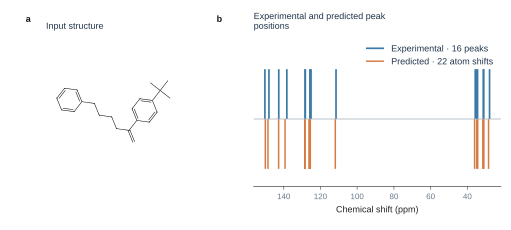

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('nmr.forward.13C', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## 运行模型

按任务指南配置环境和权重，在 benchmark runner 中选择本任务，即可评估自己的数据集。

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks nmr.forward.13C --limit 8 --output results/nmr-forward-13C.json
```

[Task](../tasks/nmr-forward-13C.md) · [Quick start](../quickstart.md)



## 参考文献

- Xu, F., Guo, W., Wang, F., Yao, L., Wang, H., Tang, F., Gao, Z., Zhang, L., E, W., Tian, Z.-Q., et al. Toward a unified benchmark and framework for deep learning-based prediction of nuclear magnetic resonance chemical shifts. Nature Computational Science 5, 292–300 (2025). doi:10.1038/s43588-025-00783-z. [Source](https://doi.org/10.1038/s43588-025-00783-z)
- OpenDataLab. WanJuan MolSpectra, version 1.0.3. Experimental molecular spectroscopy dataset. [Source](https://opendatalab.com/)
